In [51]:
import pandas as pd
data = pd.read_csv(
    r"/Users/yuxin/Documents/NYU DS/NYU-DS/2026 Fall/ML in Finance/Project/codebase/finance_term_project/data/raw/train-2025.csv",
    low_memory=False,
).drop(columns=["Unnamed: 0"], errors="ignore")

# Keep this list before adding region/province lookup columns later in the notebook.
RAW_COLUMNS = data.columns.tolist()

In [52]:
data[data["debt_st"]<0][["id", "stmt_date"]].sort_values(by="stmt_date", ascending=False)

,id,stmt_date
12413,113020259,2012-12-31
28545,175170737,2012-12-31
54095,280780131,2012-12-31
56134,289680266,2012-12-31
75403,404730319,2012-12-31
...,...,...
901271,9231601007,2007-12-31
902057,9256490013,2007-12-31
932452,11358980156,2007-12-31
953027,80007090691,2007-12-31


### Understanding the Raw columns

#### Sample Analysis

In [53]:
data.groupby(["fs_year"]).agg(n_companies=("id", "count"))

,n_companies
fs_year,
2007,144528
2008,161863
2009,171150
2010,175399
2011,184973
2012,185639


In [54]:
company_record_distribution = (
    data.groupby("id")
    .size()
    .value_counts()
    .sort_index()
    .rename_axis("n_yearly_records")
    .reset_index(name="n_companies")
)

company_record_distribution

,n_yearly_records,n_companies
0,1,29963
1,2,25870
2,3,23149
3,4,22412
4,5,35148
5,6,101169


#### HQ_city

In [55]:
len(data['HQ_city'].dropna().drop_duplicates())

110

In [57]:
region_group = pd.read_csv(r"/Users/yuxin/Documents/NYU DS/NYU-DS/2026 Fall/ML in Finance/Project/codebase/finance_term_project/data/interim/HQ_city_code_to_province_region.csv")

In [58]:
data["HQ_city"] = pd.to_numeric(data["HQ_city"])
data = pd.merge(data, region_group, how="left", left_on="HQ_city", right_on="HQ_city")
data

,id,stmt_date,HQ_city,legal_struct,ateco_sector,def_date,fs_year,asst_intang_fixed,asst_tang_fixed,asst_fixed_fin,...,days_rec,ebitda,roa,roe,wc_net,margin_fin,cf_operations,province,region,region_code
0,520288,2011-12-31,28.0,SRL,14.0,NaN,2011,67537.0,1137566.0,1908.0,...,NaN,6318.0,-3.81,-28.03,496258.0,-917029.0,-849.0,PADOVA,Veneto,5.0
1,520288,2008-12-31,28.0,SRL,14.0,NaN,2008,256438.0,1181416.0,860.0,...,NaN,46088.0,-2.76,NaN,97952.0,NaN,-3881.0,PADOVA,Veneto,5.0
2,520288,2009-12-31,28.0,SRL,14.0,NaN,2009,194046.0,1152014.0,860.0,...,NaN,67611.0,-2.17,NaN,-210671.0,NaN,32618.0,PADOVA,Veneto,5.0
3,520288,2012-12-31,28.0,SRL,14.0,NaN,2012,15195.0,1116938.0,2023.0,...,NaN,-161478.0,-12.99,NaN,367892.0,-1094962.0,-168907.0,PADOVA,Veneto,5.0
4,520288,2007-12-31,28.0,SRL,14.0,NaN,2007,126603.0,1127807.0,620.0,...,NaN,153060.0,6.20,52.43,-317007.0,-1184970.0,80039.0,PADOVA,Veneto,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1023547,92001230520,2011-12-31,52.0,SPA,93.0,NaN,2011,1498628.0,248233.0,163477.0,...,-15.33,984567.0,2.16,-43.00,204689.0,-1286111.0,550755.0,SIENA,Toscana,9.0
1023548,92001230520,2008-12-31,52.0,SPA,93.0,NaN,2008,2465065.0,343015.0,43477.0,...,23.01,1746442.0,12.97,1.01,-472335.0,-2212557.0,945705.0,SIENA,Toscana,9.0
1023549,92001230520,2007-12-31,52.0,SPA,93.0,NaN,2007,2375606.0,261775.0,28642.0,...,33.64,1539957.0,6.15,0.62,-78424.0,-2033489.0,1166064.0,SIENA,Toscana,9.0
1023550,94111750108,2010-12-31,10.0,SRL,68.0,NaN,2010,2973.0,1131586.0,264600.0,...,NaN,-4795.0,-0.31,-1.85,148203.0,-1140392.0,-4793.0,GENOVA,Liguria,7.0


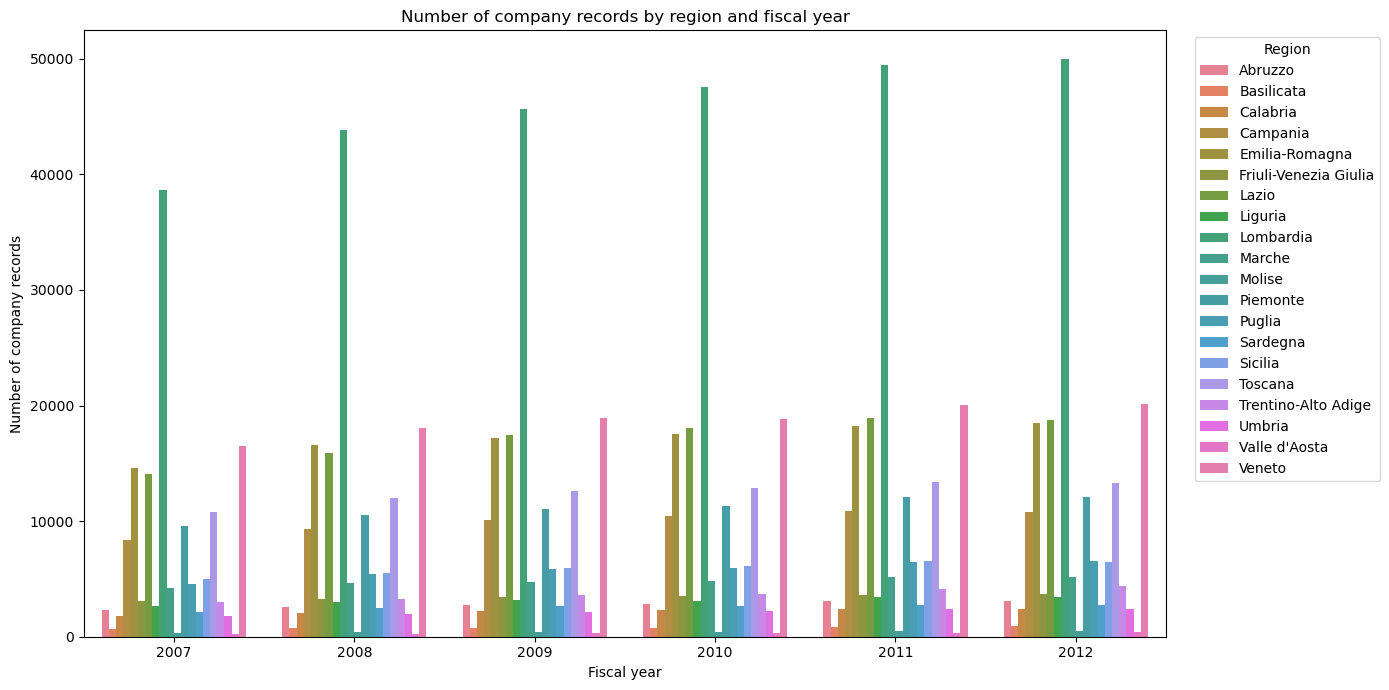

In [59]:
import seaborn as sns
import matplotlib.pyplot as plt

data.groupby(["region", "fs_year"]).agg(n_companies=("id", "count"))

company_counts = (
    data.groupby(["region", "fs_year"])
    .agg(n_companies=("id", "count"))
    .reset_index()
)

plt.figure(figsize=(14, 7))
sns.barplot(
    data=company_counts,
    x="fs_year",
    y="n_companies",
    hue="region",
    errorbar=None,
)

plt.title("Number of company records by region and fiscal year")
plt.xlabel("Fiscal year")
plt.ylabel("Number of company records")
plt.legend(title="Region", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

#### legal_struct

#### asst_intang_fixed

#### asst_fixed_fin

#### ateco_sector

## Complete raw-column EDA

Run the next two cells after loading `data`. They report every original raw column in English. Anomaly counts reproduce the rules in `01_flag_anomalies.ipynb`. For continuous financial variables, an outlier is a finite value outside the modified Tukey fences based on the 20th and 80th percentiles: `p20 - 1.5 × (p80 - p20)` or `p80 + 1.5 × (p80 - p20)`. The box plot uses that requested 20%–80% box. Identifiers, dates, and category codes are not assigned numerical outlier counts.

The final optional section provides one additional diagnostic for continuous variables: their median and missingness rate by fiscal year.

In [60]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Work only with the columns present in the initially loaded raw file.
raw_data = data.loc[:, RAW_COLUMNS].copy()

DEBT_DETAIL = ["debt_bank_st", "debt_bank_lt", "debt_fin_st", "debt_fin_lt", "AP_st", "AP_lt"]
NEG_BS_COLS = [
    "asst_intang_fixed", "asst_tang_fixed", "asst_fixed_fin", "AR",
    "liab_lt", "liab_lt_emp", *DEBT_DETAIL, "debt_st", "debt_lt",
]

# Per-column anomaly masks mirror the existing project anomaly definitions.
def make_column_anomaly_masks(frame):
    masks = {column: pd.Series(False, index=frame.index) for column in frame.columns}
    numeric_columns = [
        *NEG_BS_COLS, "rev_operating", "COGS", "exp_financing", "ebitda",
        "prof_operations", "prof_financing", "goodwill",
    ]
    values = frame.reindex(columns=numeric_columns).apply(pd.to_numeric, errors="coerce")

    for column in set(NEG_BS_COLS).intersection(masks):
        masks[column] |= values[column].lt(0)
    for column in ["rev_operating", "COGS", "exp_financing"]:
        if column in masks:
            masks[column] |= values[column].lt(0)
    if "goodwill" in masks:
        masks["goodwill"] |= values["goodwill"].lt(0)
    if "prof_financing" in masks:
        masks["prof_financing"] |= values["prof_financing"].notna() & values["prof_financing"].ne(0)

    ebitda_inconsistent = values["ebitda"].lt(values["prof_operations"])
    for column in ["ebitda", "prof_operations"]:
        if column in masks:
            masks[column] |= ebitda_inconsistent

    short_detail = values["debt_bank_st"] + values["debt_fin_st"] + values["AP_st"]
    long_detail = values["debt_bank_lt"] + values["debt_fin_lt"] + values["AP_lt"]
    detail_complete = values[DEBT_DETAIL].notna().all(axis=1)
    short_inconsistent = detail_complete & short_detail.gt(values["debt_st"] + 1)
    long_inconsistent = detail_complete & long_detail.gt(values["debt_lt"] + 1)
    for column in ["debt_bank_st", "debt_fin_st", "AP_st", "debt_st"]:
        if column in masks:
            masks[column] |= short_inconsistent
    for column in ["debt_bank_lt", "debt_fin_lt", "AP_lt", "debt_lt"]:
        if column in masks:
            masks[column] |= long_inconsistent
    return masks

COLUMN_ANOMALIES = make_column_anomaly_masks(raw_data)
DATE_COLUMNS = {"stmt_date", "def_date", "pred_start_dt"}
CATEGORY_COLUMNS = {"id", "HQ_city", "legal_struct", "ateco_sector", "fs_year", "label"}

def continuous_values(series):
    return pd.to_numeric(series, errors="coerce").replace([np.inf, -np.inf], np.nan)

def modified_tukey_outliers(values):
    values = values.dropna()
    if values.nunique() < 2:
        return pd.Series(False, index=values.index), (np.nan, np.nan)
    p20, p80 = values.quantile([0.20, 0.80])
    spread = p80 - p20
    lower, upper = p20 - 1.5 * spread, p80 + 1.5 * spread
    return (values.lt(lower) | values.gt(upper)), (lower, upper)

def raw_eda_summary(column):
    series = raw_data[column]
    n_missing = int(series.isna().sum())
    n_anomalies = int(COLUMN_ANOMALIES[column].sum())
    if column in DATE_COLUMNS or column in CATEGORY_COLUMNS:
        n_outliers = "N/A"
    else:
        outlier_mask, _ = modified_tukey_outliers(continuous_values(series))
        n_outliers = int(outlier_mask.sum())
    return pd.DataFrame({
        "variable": [column],
        "n_missing": [n_missing],
        "pct_missing": [round(100 * n_missing / len(raw_data), 2)],
        "n_anomalies": [n_anomalies],
        "n_outliers": [n_outliers],
    })

def numerical_summary(series, column):
    values = continuous_values(series).dropna()
    mode = values.mode()
    return pd.DataFrame({
        "variable": [column],
        "mean": [values.mean()], "mode": [mode.iloc[0] if not mode.empty else np.nan],
        "std": [values.std()], "min": [values.min()],
        "p10": [values.quantile(0.10)], "p20": [values.quantile(0.20)],
        "p25": [values.quantile(0.25)], "median": [values.median()],
        "p75": [values.quantile(0.75)], "p80": [values.quantile(0.80)],
        "p90": [values.quantile(0.90)], "max": [values.max()],
    }).round(4)

def categorical_summary(series, column):
    observed = series.dropna()
    mode = observed.mode()
    return pd.DataFrame({
        "variable": [column], "n_observed": [len(observed)],
        "n_unique": [observed.nunique()],
        "mode": [mode.iloc[0] if not mode.empty else np.nan],
        "mode_count": [int(observed.eq(mode.iloc[0]).sum()) if not mode.empty else 0],
    })

def plot_continuous_variable(series, column):
    values = continuous_values(series).dropna()
    if values.empty:
        print("No observed numeric values to plot.")
        return
    p01, p99 = values.quantile([0.01, 0.99])
    shown = values.clip(p01, p99)
    outlier_mask, (lower, upper) = modified_tukey_outliers(values)
    p20, median, p80 = values.quantile([0.20, 0.50, 0.80])

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    sns.histplot(shown, bins=40, ax=axes[0], color="#4C78A8")
    axes[0].set_title(f"Empirical distribution: {column}")
    axes[0].set_xlabel(f"{column} (display clipped to p1–p99)")
    axes[0].set_ylabel("Number of records")

    inliers = values[~outlier_mask]
    axes[1].bxp([{
        "label": column, "whislo": inliers.min(), "q1": p20, "med": median,
        "q3": p80, "whishi": inliers.max(),
        "fliers": values[outlier_mask].sample(min(1_000, int(outlier_mask.sum())), random_state=42).tolist(),
    }], showfliers=True)
    axes[1].set_title(f"20th–80th percentile box plot: {column}")
    axes[1].set_ylabel(column)
    plt.tight_layout()
    plt.show()
    print(f"Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [{lower:,.4g}, {upper:,.4g}].")

def plot_categorical_variable(series, column):
    if column in DATE_COLUMNS:
        values = pd.to_datetime(series, errors="coerce").dt.year
        xlabel = "Year"
    else:
        values = series.astype("string")
        xlabel = column
    counts = values.value_counts(dropna=False).head(20).sort_values()
    plt.figure(figsize=(10, max(4, 0.32 * len(counts))))
    sns.barplot(x=counts.values, y=counts.index.astype(str), color="#4C78A8")
    plt.title(f"Empirical distribution: {column} (top 20 categories)")
    plt.xlabel("Number of records")
    plt.ylabel(xlabel)
    plt.tight_layout()
    plt.show()

def show_raw_column_eda(column, show_yearly_diagnostic=True):
    display(Markdown(f"### {column}"))
    display(Markdown("**1. Missing values, anomalies, and outliers**"))
    display(raw_eda_summary(column))
    display(Markdown("**2. Summary statistics**"))
    if column in DATE_COLUMNS or column in CATEGORY_COLUMNS:
        display(categorical_summary(raw_data[column], column))
        display(Markdown("Mean, standard deviation, percentiles, and numerical outliers are not meaningful for this identifier, date, or categorical code."))
        display(Markdown("**3. Empirical distribution**"))
        plot_categorical_variable(raw_data[column], column)
    else:
        display(numerical_summary(raw_data[column], column))
        display(Markdown("**3–4. Empirical distribution and 20th–80th percentile box plot**"))
        plot_continuous_variable(raw_data[column], column)
        if show_yearly_diagnostic and "fs_year" in raw_data:
            display(Markdown("**5. Additional diagnostic: median and missingness by fiscal year**"))
            yearly = raw_data.groupby("fs_year")[column].agg(
                n_observed=lambda x: x.notna().sum(),
                pct_missing=lambda x: round(100 * x.isna().mean(), 2),
                median=lambda x: continuous_values(x).median(),
            )
            display(yearly.round(4))


### id

**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,id,0,0.0,0,N/A


**2. Summary statistics**

,variable,n_observed,n_unique,mode,mode_count
0,id,1023552,237711,520288,6


Mean, standard deviation, percentiles, and numerical outliers are not meaningful for this identifier, date, or categorical code.

**3. Empirical distribution**

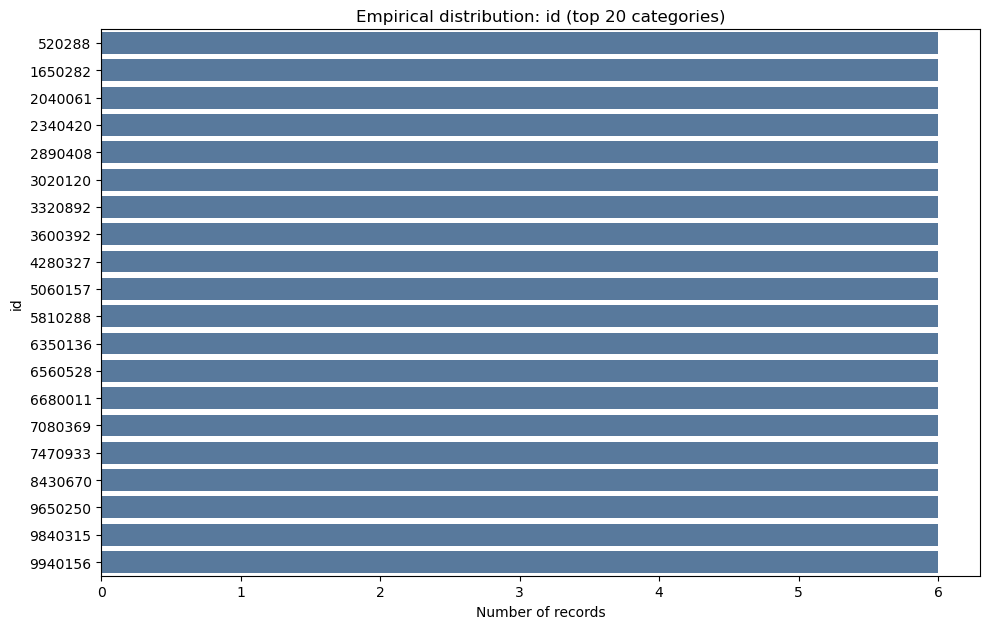

### stmt_date

**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,stmt_date,0,0.0,0,N/A


**2. Summary statistics**

,variable,n_observed,n_unique,mode,mode_count
0,stmt_date,1023552,6,2012-12-31,185639


Mean, standard deviation, percentiles, and numerical outliers are not meaningful for this identifier, date, or categorical code.

**3. Empirical distribution**

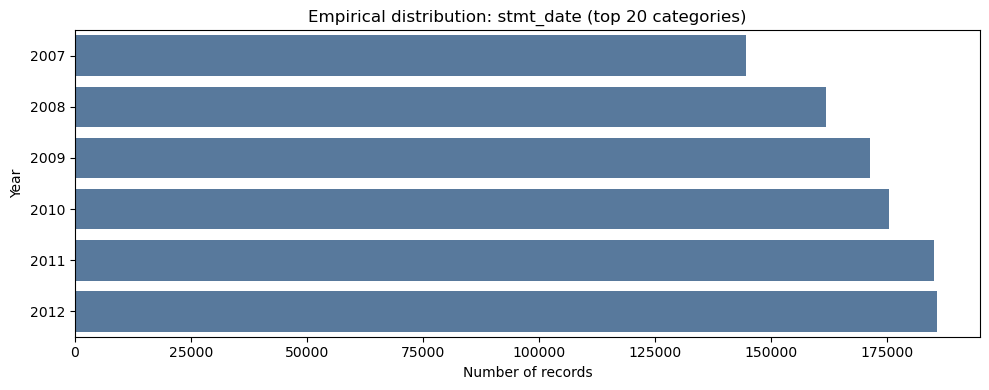

### HQ_city

**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,HQ_city,277,0.03,0,N/A


**2. Summary statistics**

,variable,n_observed,n_unique,mode,mode_count
0,HQ_city,1023275,110,15.0,122090


Mean, standard deviation, percentiles, and numerical outliers are not meaningful for this identifier, date, or categorical code.

**3. Empirical distribution**

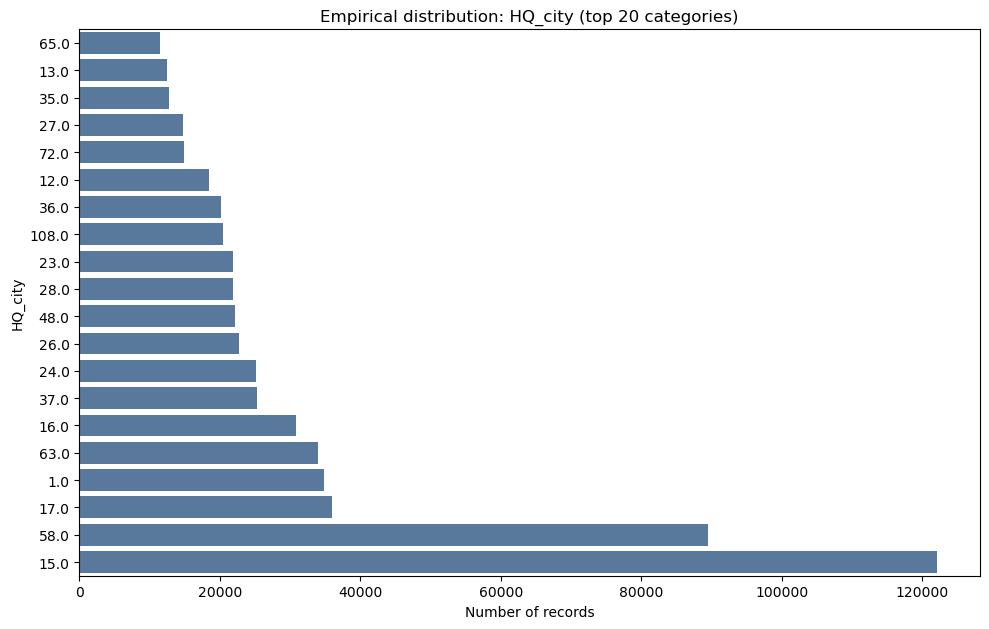

### legal_struct

**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,legal_struct,0,0.0,0,N/A


**2. Summary statistics**

,variable,n_observed,n_unique,mode,mode_count
0,legal_struct,1023552,6,SRL,738994


Mean, standard deviation, percentiles, and numerical outliers are not meaningful for this identifier, date, or categorical code.

**3. Empirical distribution**

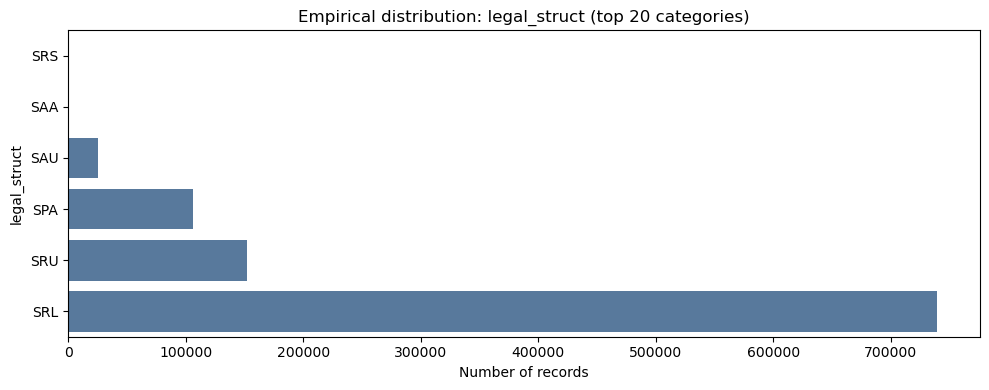

### ateco_sector

**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,ateco_sector,0,0.0,0,N/A


**2. Summary statistics**

,variable,n_observed,n_unique,mode,mode_count
0,ateco_sector,1023552,83,68.0,199387


Mean, standard deviation, percentiles, and numerical outliers are not meaningful for this identifier, date, or categorical code.

**3. Empirical distribution**

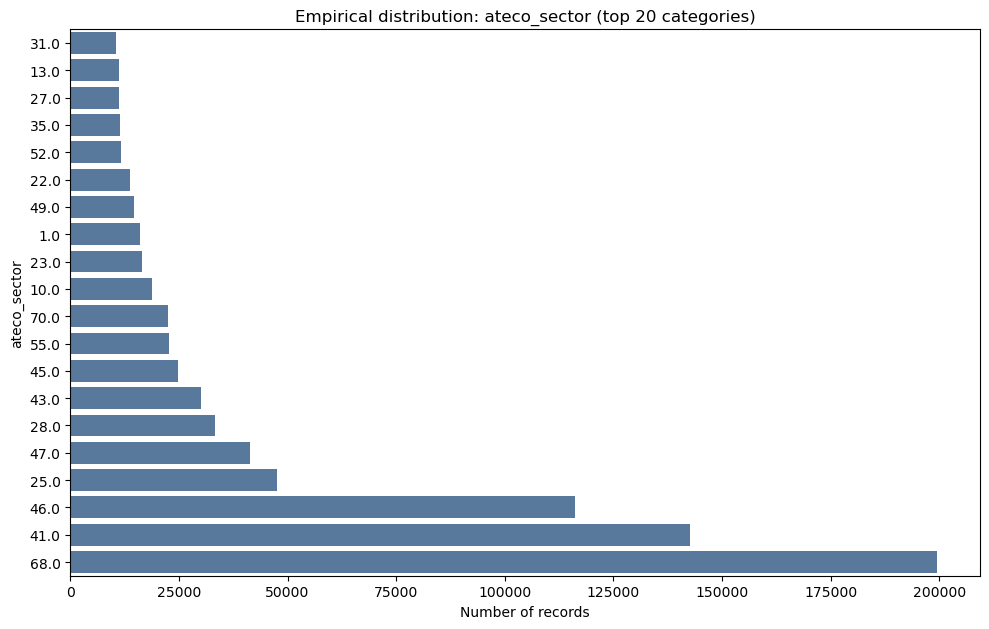

### def_date

**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,def_date,978827,95.63,0,N/A


**2. Summary statistics**

,variable,n_observed,n_unique,mode,mode_count
0,def_date,44725,1467,2012-12-20,288


Mean, standard deviation, percentiles, and numerical outliers are not meaningful for this identifier, date, or categorical code.

**3. Empirical distribution**

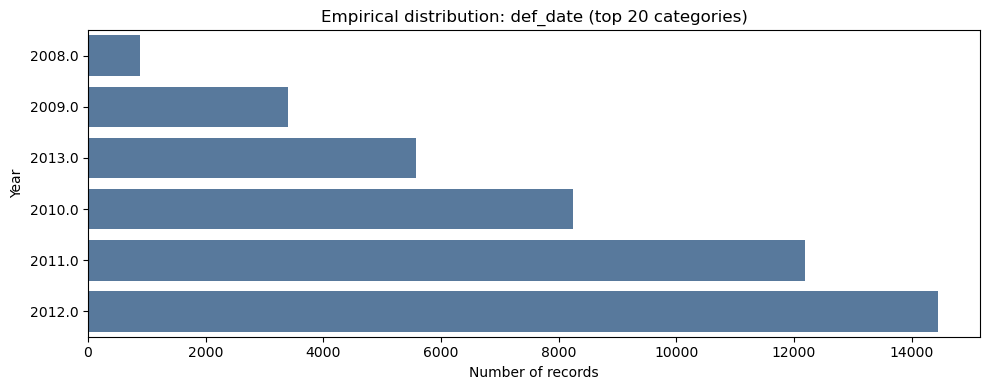

### fs_year

**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,fs_year,0,0.0,0,N/A


**2. Summary statistics**

,variable,n_observed,n_unique,mode,mode_count
0,fs_year,1023552,6,2012,185639


Mean, standard deviation, percentiles, and numerical outliers are not meaningful for this identifier, date, or categorical code.

**3. Empirical distribution**

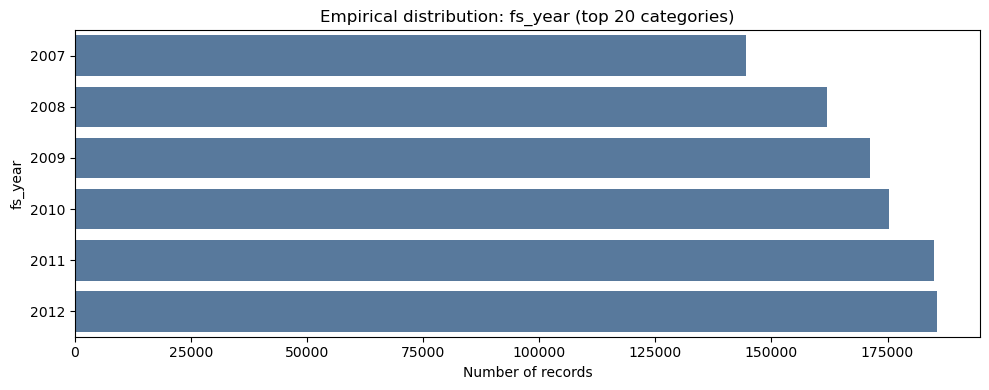

### asst_intang_fixed

**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,asst_intang_fixed,162,0.02,799,117998


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,asst_intang_fixed,468404.7429,0.0,1.486886e+07,-3442959.0,0.0,0.0,262.0,7975.0,75156.75,119836.0,364399.1,3.708467e+09


**3–4. Empirical distribution and 20th–80th percentile box plot**

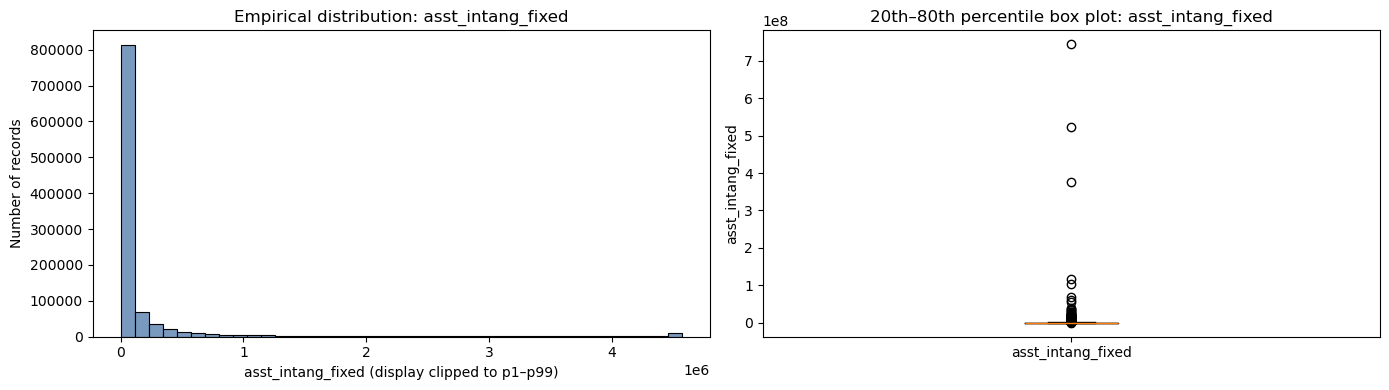

Display histogram is clipped to p1–p99; modified-Tukey outlier fences: [-1.798e+05, 2.996e+05].


**5. Additional diagnostic: median and missingness by fiscal year**

,n_observed,pct_missing,median
fs_year,,,
2007,144509,0.01,9550.0
2008,161831,0.02,8253.0
2009,171040,0.06,7793.0
2010,175398,0.00,7473.0
2011,184973,0.00,7545.0
2012,185639,0.00,7540.0


### asst_tang_fixed

**1. Missing values, anomalies, and outliers**

,variable,n_missing,pct_missing,n_anomalies,n_outliers
0,asst_tang_fixed,103,0.01,318,77514


**2. Summary statistics**

,variable,mean,mode,std,min,p10,p20,p25,median,p75,p80,p90,max
0,asst_tang_fixed,3.411074e+06,0.0,1.293634e+08,-1711468.0,210.0,34411.6,66631.0,595899.0,2064874.0,2636963.4,5126046.4,5.822144e+10


**3–4. Empirical distribution and 20th–80th percentile box plot**

In [ ]:
# Full report for every raw column. This deliberately excludes only the exported CSV index.
for column in RAW_COLUMNS:
    show_raw_column_eda(column)